# Nama    : Ferdynand Rayner Auryo
# NIM     : 2802546683
# Course  : Text Mining

In [121]:
# Cell untuk menginstall
!pip install google-play-scraper
!pip install emoji
!pip install gensim
!pip install google-play-scraper emoji imbalanced-learn

# Import Cell

In [122]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import unicodedata
import nltk
from nltk import pos_tag, word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from google_play_scraper import reviews, Sort

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import emoji
for r in ["punkt", "punkt_tab", "stopwords", "wordnet",
          "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(r)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


# 1. Scrapping
Saya memilih aplikasi Crunchyroll karena saya belakangan ini tertarik dengan menonton Anime oleh dan Crunchyroll umumnya digunakan untuk menonton Anime

In [123]:
# Cell scraping review Crunchyroll di Play Store
# SCRAPE = True hanya dipakai saat pertama kali mengambil data.
# Kalau False, notebook memakai reviews.csv yang sudah ada.
SCRAPE = False

app_id = "com.crunchyroll.crunchyroid"

if SCRAPE:
    result, _ = reviews(
        app_id,
        lang="en",
        country="us",
        sort=Sort.NEWEST,
        count=1000,
    )
    pd.DataFrame(result)[["content", "score", "at"]].to_csv("reviews.csv", index=False)

# Untuk Read CSV
df = pd.read_csv("reviews.csv")
print(df.shape)
print(df["score"].value_counts().sort_index())

(1000, 3)
score
1    370
2     75
3     76
4     98
5    381
Name: count, dtype: int64


In [124]:
# Simpan ke csv jika menggunakan google colab
# df.to_csv("reviews.csv", index=False)
# from google.colab import files
# files.download("reviews.csv")

In [125]:
# Print shape data frame
# df = pd.read_csv("data/reviews.csv")
# print(df.shape)
# print(df["score"].value_counts().sort_index())

In [126]:
# !mkdir -p data
# !mv reviews.csv data/reviews.csv
# !ls data

# 2. Exploratory

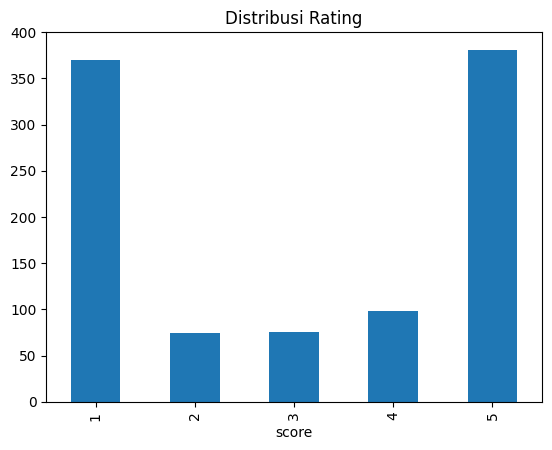

1 mentah: [('the', 344), ('to', 303), ('i', 300), ('and', 249), ('it', 201), ('is', 186), ('for', 155), ('app', 155), ('a', 147), ('this', 124)]
1 tanpa stopword: [('app', 155), ('not', 112), ('anime', 97), ('watch', 95), ('subscription', 70), ('even', 70), ('no', 65), ('crunchyroll', 48), ('premium', 46), ("can't", 44), ('free', 42), ('still', 42), ('one', 38), ('pay', 34), ('money', 33)] 

2 mentah: [('the', 90), ('i', 71), ('to', 60), ('and', 49), ('it', 46), ('is', 45), ('app', 36), ('in', 35), ('of', 35), ('a', 31)]
2 tanpa stopword: [('app', 36), ('not', 30), ('anime', 19), ('no', 13), ('even', 13), ('streaming', 12), ('watch', 12), ('please', 11), ('picture', 11), ('english', 10), ('subscription', 10), ('like', 10), ('get', 9), ('work', 8), ('always', 8)] 

3 mentah: [('the', 96), ('i', 75), ('to', 67), ('and', 61), ('it', 55), ('is', 49), ('a', 46), ('in', 42), ('app', 41), ('not', 39)]
3 tanpa stopword: [('app', 41), ('not', 39), ('anime', 31), ('good', 20), ('available', 16),

In [127]:
def tokenize(text):
    return re.findall(r"[a-z']+", str(text).lower())

stop_eda = set(stopwords.words("english")) - {"not", "no", "nor", "never"}

# distribusi rating
df["score"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribusi Rating"); plt.show()

# kata dominan per rating, sebelum dan sesudah stopword dibuang
for s in range(1, 6):
    raw, filt = Counter(), Counter()
    for t in df.loc[df["score"] == s, "content"]:
        toks = tokenize(t)
        raw.update(toks)
        filt.update(w for w in toks if w not in stop_eda and len(w) > 1)
    print(s, "mentah:", raw.most_common(10))
    print(s, "tanpa stopword:", filt.most_common(15), "\n")

# kata non-baku
all_words = Counter(w for t in df["content"] for w in tokenize(t))
nonstd = ["u", "ur", "pls", "plz", "cuz", "bc", "lol", "gr8", "dont", "cant", "doesnt", "im", "ive"]
print({w: all_words.get(w, 0) for w in nonstd})

# Cek emoji untuk menentukan keputusan
has_emoji = df["content"].apply(lambda t: emoji.emoji_count(str(t)) > 0)
print(has_emoji.sum(), "dari", len(df), "review mengandung emoji")
print(df[has_emoji]["score"].value_counts().sort_index())
print("Persenan Emoji setiap", has_emoji.groupby(df["score"]).mean().round(3))

Hasil dari EDA di atas menemukan bahwa ditemukannya class imbalance antara Score 1 dan 5 dengan score 2, 3, 4 jadi menilai menggunakan accuracy saja tidak cukup. Top 10 kata dominan sebelum stopword dan top 15 kata dominan setelah stopword. Stopword harus dibuang dan 145 dari 1000 data menghasilkan emoji yang dimana memerlukan menurut saya harus di convert menjadi teks karena akan berpengaruh terhadap sentimen

Pada cell di bawah saya melakukan deteksi terhadap aksara setiap review yang dimana ditemukan aksara lain seperti THAI, ARABIC, dll.

Saya juga melakukan deteksi terhadap huruf yang terpisah pisah

In [128]:
# 1. Deteksi aksara (script) tiap review
def scripts_in(text):
    found = set()
    for ch in str(text):
        if ch.isalpha():
            name = unicodedata.name(ch, "")
            found.add(name.split()[0] if name else "UNKNOWN")
    return found

df["scripts"] = df["content"].apply(scripts_in)

# hitung berapa review yang memuat tiap aksara
script_count = Counter(s for sc in df["scripts"] for s in sc)
print(script_count)

# review yang mengandung aksara selain LATIN
non_latin = df["scripts"].apply(lambda s: bool(s - {"LATIN"}))
print(non_latin.sum(), "review mengandung aksara non-Latin")
print(df[non_latin]["score"].value_counts().sort_index())
for _, r in df[non_latin].iterrows():
    print(r["score"], sorted(r["scripts"]), "|", r["content"][:60])

# Deteksi huruf yang dipisah spasi
spaced = df["content"].str.contains(r"\b(?:[A-Za-z] ){2,}[A-Za-z]\b", regex=True)
print(spaced.sum(), "review dengan huruf dipisah spasi")
print(df[spaced][["content", "score"]])

Counter({'LATIN': 980, 'DEVANAGARI': 3, 'ARABIC': 2, 'BENGALI': 2, 'GUJARATI': 1, 'CYRILLIC': 1, 'THAI': 1, 'MATHEMATICAL': 1})
11 review mengandung aksara non-Latin
score
1    4
4    1
5    6
Name: count, dtype: int64
1 ['GUJARATI'] | અઃઅંગચ થઈ થ
1 ['DEVANAGARI', 'LATIN'] | हिंदी dubbing कम हे ओर जिस एनिमल सिरीज में हिंदी डबिंग थोडा 
5 ['DEVANAGARI', 'LATIN'] | please 😔🙏🏻 हिंदी dub please
5 ['DEVANAGARI'] | बेस्ट एपक्रंचायरॉल
5 ['CYRILLIC', 'LATIN'] | Оперативная доставка сущностей по UID.
1 ['THAI'] | ดูอะไรไม่ได้
5 ['ARABIC'] | ووتمو
4 ['ARABIC'] | واو
5 ['BENGALI'] | দেব সিংহ
1 ['MATHEMATICAL'] | 𝚋𝚘𝚛𝚎𝚍
5 ['BENGALI'] | অনেক ধন্যবাদ
1 review dengan huruf dipisah spasi
     content  score
296  B e s t      5


Pada cell di bawah ini saya membuat daftar kata slang/singkatan untuk menentukan kata kata mana saja yang perlu diperahtikan, saya juga menghitung total token dari seluruh dataset disini, dan mencari kata yang hanya muncul sekali

In [129]:
all_words = Counter()
for t in df["content"]:
    all_words.update(tokenize(t))

# daftar slang/singkatan contoh
nonstd = ["u", "ur", "pls", "plz", "cuz", "bc", "lol", "gr8", "dont", "cant", "doesnt", "im", "ive"]
for w in nonstd:
    print(w, all_words.get(w, 0))
total = sum(all_words.values())
nonstd_total = sum(all_words.get(w, 0) for w in nonstd)
print(f"Kata non-baku: {nonstd_total} dari {total} token ({nonstd_total/total:.2%})")

# kandidat lain: kata yang sangat jarang muncul (sering typo)
print([w for w, c in all_words.items() if c == 1][:50])

u 16
ur 4
pls 18
plz 3
cuz 0
bc 0
lol 1
gr8 0
dont 9
cant 16
doesnt 1
im 10
ive 5
Kata non-baku: 83 dari 21068 token (0.39%)
['malicious', 'st', 'july', 'november', 'screenshots', 'advantage', 'forgetful', 'nature', 'churning', 'expert', 'dude', 'hesitant', 'regional', 'originally', 'decided', 'laid', 'desktop', 'compatible', 'moment', 'hire', 'instance', 'strike', 'witches', 'jitna', 'bekarar', 'bataun', 'baat', 'belongs', 'yakkk', 'jump', 'hoops', 'tab', 'regionlocks', 'verge', 'translating', 'yoir', 'idk', 'style', 'mangas', 'manhwa', 'foe', 'mail', 'shity', 'stucking', 'doning', 'evething', 'manually', 'frustrated', 'gregorian', 'animated']


# 3. Preprocessing

Pada tahap pertama saya akan menentukan kalimat slang terlebih dahulu yang akan diubah ke bentu artinya, saya juga menentukan stopwords bahasa Inggris dari library NLTK, bagian 'not','no','nor','never' dikecualikan karena kata ini sangat menentukan sentimen, face juga termasuk stopword karena terdapat emoji yang lebih dari 5% dari seluruh data yang dimana emoji sendiri memiliki kata 'face' cukup umum, lalu untuk exception adalah kata yang di salahartikan oleh lemmatizer(misal stuck:stick) jadi dikecualikan agar tidak salah arti

In [140]:
slang = {"u": "you", "ur": "your", "pls": "please", "plz": "please",
         "im": "i am", "ive": "i have", "dont": "do not", "cant": "can not",
         "doesnt": "does not", "idk": "i do not know"}

stop = set(stopwords.words("english")) - {"not", "no", "nor", "never"}
stop = stop | {"face"}
exceptions = {"stuck": "stuck", "worst": "worst", "us": "us","best": "best", "bored": "bored"}
lemmatizer = WordNetLemmatizer()

Pada cell ini saya melakukan beberapa bagian preprocessing yaitu dengan melakukan convert emoji menggunakan library "emoji", saya juga melakukan perubahan kata kata singkatan menjadi bentuk aslinya, dan saya juga menentukan jenis kata (Part of Speech/POS) agar proses Lemmatization dapat dilakukan dengan lebih akurat menggunakan WordNet. Lalu fungsi terakhir adalah fungsi untuk menjalankan preprocessingnya, unicodedata digunakan untuk menggabungkan karakter Unicode agar bentuk menjadi konsisten, lowercase huruf kapital, menggabungkan kata terpisah, menghapus alamat URL, menghapus simbol(excl. huruf & space), tokenization, normalize slang, menentukan kata POS

In [131]:
# Fungsi untuk convert emoji
def convert_emoji(text):
    text = emoji.demojize(text, delimiters=(" ", " "))
    return text.replace("_", " ")
# Fungsi untuk mengubah kata2 singkatan menjadi bentuk aslinya
def expand_contractions(text):
    text = text.replace("can't", "can not").replace("won't", "will not")
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"'m\b", " am", text)
    text = re.sub(r"'ve\b", " have", text)
    return text
# Fungsi untuk membantu menentukan jenis kata
def get_wordnet_pos(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

def preprocess(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = re.sub(r"\b(?:[a-z] ){2,}[a-z]\b",
                  lambda m: m.group(0).replace(" ", ""), text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = convert_emoji(text)
    text = expand_contractions(text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [t for w in tokens for t in slang.get(w, w).split()]
    tagged = pos_tag(tokens)
    result = []
    for word, tag in tagged:
        if word in stop or len(word) < 2:
            continue
        lemma = lemmatizer.lemmatize(word, get_wordnet_pos(tag))
        result.append(exceptions.get(word, lemma))
    return result

Pada cell terakhir dalam preprocessing, adalah cell untuk menjalankan semua fungsi di cell sebelumnya agar dapat memperoleh dataset versi cleaned nya, saya juga melampirkan berapa cell kosong yang ditemukan yang ternyata cell kosong tersebut berisi sebuah kata non latin yang sudah di handle sebelumnya

In [132]:
df["tokens"] = df["content"].apply(preprocess)
df["clean"] = df["tokens"].apply(lambda x: " ".join(x))

kosong = df[df["tokens"].str.len() == 0]
print(len(kosong), "review kosong")
print(kosong[["content", "score"]])

print("Sebelum:", df["score"].value_counts().sort_index().tolist())
df = df[df["tokens"].str.len() > 0].reset_index(drop=True)
print("Sesudah:", df["score"].value_counts().sort_index().tolist(), len(df))

df.to_csv("reviews_clean.csv", index=False)

7 review kosong
                content  score
76          અઃઅંગચ થઈ થ      1
279  बेस्ट एपक्रंचायरॉल      5
392        ดูอะไรไม่ได้      1
440               ووتمو      5
542                 واو      4
698            দেব সিংহ      5
901        অনেক ধন্যবাদ      5
Sebelum: [370, 75, 76, 98, 381]
Sesudah: [368, 75, 76, 97, 377] 993


# 4. Text Representation

Pada tahap ini saya melakukan text Representation menggunakan TfidfVectorizer dan Word2Vec, TfidfVectorizer digunakan karena dapat mengukur seberapa penting suatu kata dalam suatu review dan metode Word2Vect digunakan karena merupakan metode word embedding yang mempelajari representasi vektor suatu kata berdasarkan konteks kata-kata di sekitarnya dengan menggunakan Neural Network (ANN). Word2Vec yang saya pakai menggunakan arsitektur skip-gram, yang dimana model akan belajar berdasarkan kata kata input disekitar kata target

In [134]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec

X_train, X_test, y_train, y_test = train_test_split(
    df["tokens"], df["score"], test_size=0.2, stratify=df["score"], random_state=42
)

# Metode 1: TF-IDF (nilai vektor = seberapa penting kata dalam suatu review)
tfidf = TfidfVectorizer(min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train.apply(" ".join))
X_test_tfidf = tfidf.transform(X_test.apply(" ".join))

# Metode 2: Word2Vec skip-gram (kata input memprediksi kata di sekitarnya)
w2v = Word2Vec(sentences=X_train.tolist(), vector_size=100, window=5,
               min_count=2, sg=1, epochs=20, seed=42)

def doc_vec(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

X_train_w2v = np.vstack(X_train.apply(doc_vec))
X_test_w2v = np.vstack(X_test.apply(doc_vec))

print(X_train_tfidf.shape, X_train_w2v.shape)

(794, 862) (794, 100)


## 5. Modeling and Tuning

Bagian awal modeling saya gunakan StratifiedFold untuk membagi data training untuk proses Cross-Validation, saya menggunakan 2 model machine learning yaitu Logistic Regression dan Random Forest

In [135]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"C": [0.1, 1, 10], "solver": ["liblinear", "lbfgs"]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {"n_estimators": [100, 300], "max_depth": [None, 20]}
    ),
}

features = {
    "TF-IDF": (X_train_tfidf, X_test_tfidf),
    "Word2Vec": (X_train_w2v, X_test_w2v),
}

results, best_models = [], {}
for rep, (Xtr, Xte) in features.items():
    for name, (model, grid) in models.items():
        gs = GridSearchCV(model, grid, cv=cv, scoring="f1_macro", n_jobs=-1)
        gs.fit(Xtr, y_train)
        pred = gs.predict(Xte)
        best_models[(rep, name)] = gs.best_estimator_
        results.append({
            "Text Representation": rep,
            "Algoritma": name,
            "Hyperparameter": str(gs.best_params_),
            "Accuracy": accuracy_score(y_test, pred),
            "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
            "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        })

res_df = pd.DataFrame(results).round(3)
res_df

,Text Representation,Algoritma,Hyperparameter,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,TF-IDF,Logistic Regression,"{'C': 10, 'solver': 'liblinear'}",0.603,0.394,0.362,0.358
1,TF-IDF,Random Forest,"{'max_depth': None, 'n_estimators': 300}",0.608,0.312,0.330,0.295
2,Word2Vec,Logistic Regression,"{'C': 10, 'solver': 'lbfgs'}",0.653,0.462,0.355,0.317
3,Word2Vec,Random Forest,"{'max_depth': None, 'n_estimators': 300}",0.658,0.371,0.358,0.322


# Performance Analysis

Dari tabel performa di atas menghasilkan bahwa Accuracy tertinggi diperoleh oleh Word2Vec + Random Forest, namun F1-score nya hanya 0.322 yang berarti model belum tentu memiliki performa klasifikasi sentimen pada setiap kelas dengan baik. Dengan TF-IDF + Logistic Regression yang memperoleh nilai F1-score yang terbesar, ini menunjukkan bahwa model ini dapat memprediksi sentimen di setiap kelas pada kata berbasis TF-IDF dengan baik

In [136]:
for (rep, name), m in best_models.items():
    Xte = features[rep][1]
    print(rep, "+", name)
    print(classification_report(y_test, m.predict(Xte), zero_division=0))

TF-IDF + Logistic Regression
              precision    recall  f1-score   support

           1       0.68      0.73      0.70        74
           2       0.33      0.13      0.19        15
           3       0.33      0.13      0.19        15
           4       0.00      0.00      0.00        19
           5       0.63      0.82      0.71        76

    accuracy                           0.60       199
   macro avg       0.39      0.36      0.36       199
weighted avg       0.54      0.60      0.56       199

TF-IDF + Random Forest
              precision    recall  f1-score   support

           1       0.62      0.74      0.67        74
           2       0.00      0.00      0.00        15
           3       0.00      0.00      0.00        15
           4       0.33      0.05      0.09        19
           5       0.61      0.86      0.71        76

    accuracy                           0.61       199
   macro avg       0.31      0.33      0.30       199
weighted avg       0.49  

In [137]:
best = best_models[("TF-IDF", "Logistic Regression")]
cm = confusion_matrix(y_test, best.predict(X_test_tfidf))
print(pd.DataFrame(cm, index=[1,2,3,4,5], columns=[1,2,3,4,5]))

    1  2  3  4   5
1  54  2  3  1  14
2   9  2  0  0   4
3   6  0  2  1   6
4   6  0  0  0  13
5   5  2  1  6  62


# 7. Handling Imbalance with SMOTE

Karena terdapat imbalance pada dataset, saya melakukan handling imbalance menggunakan SMOTE

In [138]:
print(y_train.value_counts().sort_index())   # distribusi sebelum SMOTE

results_bal, best_bal = [], {}
for rep, (Xtr, Xte) in features.items():
    for name, (model, grid) in models.items():
        pipe = ImbPipeline([("smote", SMOTE(random_state=42)), ("clf", model)])
        grid_p = {f"clf__{k}": v for k, v in grid.items()}
        gs = GridSearchCV(pipe, grid_p, cv=cv, scoring="f1_macro", n_jobs=-1)
        gs.fit(Xtr, y_train)
        pred = gs.predict(Xte)
        best_bal[(rep, name)] = gs.best_estimator_
        results_bal.append({
            "Treatment": "SMOTE",
            "Text Representation": rep,
            "Algoritma": name,
            "Hyperparameter": str(gs.best_params_),
            "Accuracy": accuracy_score(y_test, pred),
            "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
            "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        })

res_bal = pd.DataFrame(results_bal).round(3)
res_df["Treatment"] = "Tanpa SMOTE"
pd.concat([res_df, res_bal], ignore_index=True)

score
1    294
2     60
3     61
4     78
5    301
Name: count, dtype: int64


,Text Representation,Algoritma,Hyperparameter,Accuracy,Precision (macro),Recall (macro),F1 (macro),Treatment
0,TF-IDF,Logistic Regression,"{'C': 10, 'solver': 'liblinear'}",0.603,0.394,0.362,0.358,Tanpa SMOTE
1,TF-IDF,Random Forest,"{'max_depth': None, 'n_estimators': 300}",0.608,0.312,0.330,0.295,Tanpa SMOTE
2,Word2Vec,Logistic Regression,"{'C': 10, 'solver': 'lbfgs'}",0.653,0.462,0.355,0.317,Tanpa SMOTE
3,Word2Vec,Random Forest,"{'max_depth': None, 'n_estimators': 300}",0.658,0.371,0.358,0.322,Tanpa SMOTE
4,TF-IDF,Logistic Regression,"{'clf__C': 0.1, 'clf__solver': 'liblinear'}",0.497,0.392,0.381,0.377,SMOTE
5,TF-IDF,Random Forest,"{'clf__max_depth': None, 'clf__n_estimators': ...",0.618,0.518,0.423,0.442,SMOTE
6,Word2Vec,Logistic Regression,"{'clf__C': 10, 'clf__solver': 'liblinear'}",0.503,0.414,0.415,0.393,SMOTE
7,Word2Vec,Random Forest,"{'clf__max_depth': 20, 'clf__n_estimators': 100}",0.573,0.400,0.394,0.395,SMOTE


Dari hasil cell di atas memperoleh bahwa setiap model memperoleh peningkatan setelah dilakukan SMOTE, model terbaik setelah melakukan SMOTE adalah TF-IDF + Random Forest yang menunjukkan peningkatan F1-Score yang cukup pesat dari 0.295 menjadi 0.442 sekaligus menjadi model terbaik karena memiliki F1-Score tertinggi.

Namun bisa dilihat disini bahwa accuracy setiap model mengalami penurunan selain model terbaik, ini menunjukkan bahwa performa model menurun karena kurang baik dalam memprediksi sentimen pada setiap kelas, sebelumnya accuracy tinggi karena kelas yang diprediksi tinggi adalah kelas yang memiliki data mayoritas

In [139]:
for (rep, name), m in best_bal.items():
    print(rep, "+", name, "(SMOTE)")
    print(classification_report(y_test, m.predict(features[rep][1]), zero_division=0))

TF-IDF + Logistic Regression (SMOTE)
              precision    recall  f1-score   support

           1       0.70      0.65      0.67        74
           2       0.09      0.20      0.12        15
           3       0.28      0.33      0.30        15
           4       0.17      0.21      0.19        19
           5       0.74      0.51      0.60        76

    accuracy                           0.50       199
   macro avg       0.39      0.38      0.38       199
weighted avg       0.58      0.50      0.53       199

TF-IDF + Random Forest (SMOTE)
              precision    recall  f1-score   support

           1       0.67      0.73      0.70        74
           2       0.40      0.13      0.20        15
           3       0.50      0.27      0.35        15
           4       0.40      0.21      0.28        19
           5       0.62      0.78      0.69        76

    accuracy                           0.62       199
   macro avg       0.52      0.42      0.44       199
weighted 